# FX transaction exposure: natural hedge vs forward vs option (illustrative)

> **Educational analysis, not investment advice.**

**Why the numbers here are invented.** The course assignment used a fictional company supplied with the module
(round-number positions, a lecturer-defined case). Since it is not a real firm's disclosure, this notebook does not
reuse it. Instead it rebuilds the *method* on a **fully fictional company with illustrative numbers** defined in the
`fx_case` block of `assumptions.yaml`. Spot levels, volatilities, correlations and interest rates are **not market data**.

Method: (1) net monetary position per currency, (2) variance-covariance VaR with and without diversification,
(3) Monte Carlo comparison of unhedged, natural, forward and option hedges at a 6-month tenor.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from icbp_valuation import load_assumptions, load_financials
from icbp_valuation import plots

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
fin, a = load_financials(), load_assumptions()

from icbp_valuation import fx_exposure as fx
case = a["fx_case"]

## 1. Net monetary position

In [2]:
net = fx.net_positions(case)
display(net[["assets_fcy", "liabilities_fcy", "net_fcy", "spot", "net_idr", "position"]]
        .style.format({"assets_fcy": "{:,.0f}", "liabilities_fcy": "{:,.0f}", "net_fcy": "{:,.0f}",
                       "spot": "{:,.0f}", "net_idr": "{:,.0f}"}))
print(f"Gross FX assets  : IDR {net['assets_idr'].sum()/1e9:,.1f} bn   Gross FX liabilities: IDR {net['liabilities_idr'].sum()/1e9:,.1f} bn")
print(f"Net position     : IDR {net['net_idr'].sum()/1e9:,.1f} bn (negative = net short foreign currency)")

,assets_fcy,liabilities_fcy,net_fcy,spot,net_idr,position
ccy,,,,,,
USD,"1,200,000","300,000","900,000","16,500","14,850,000,000",net long (asset)
EUR,"400,000",0,"400,000","18,000","7,200,000,000",net long (asset)
CNY,0,"18,000,000","-18,000,000","2,300","-41,400,000,000",net short (liability)
JPY,0,"120,000,000","-120,000,000",110,"-13,200,000,000",net short (liability)


Gross FX assets  : IDR 27.0 bn   Gross FX liabilities: IDR 59.5 bn
Net position     : IDR -32.5 bn (negative = net short foreign currency)


The book is net **short** CNY and JPY (import payables) and net **long** USD and EUR (export receivables). Long and short
positions in different currencies partly offset only to the extent the currencies co-move, which is what the VaR step measures.

## 2. Value at risk (1 year, 99%, variance-covariance)

,stand-alone VaR (IDR bn)
USD,2.76
EUR,1.67
CNY,5.78
JPY,3.38


Sum of stand-alone VaRs (no diversification): IDR 13.60 bn
Diversified portfolio VaR                    : IDR 5.60 bn  (z = 2.326)


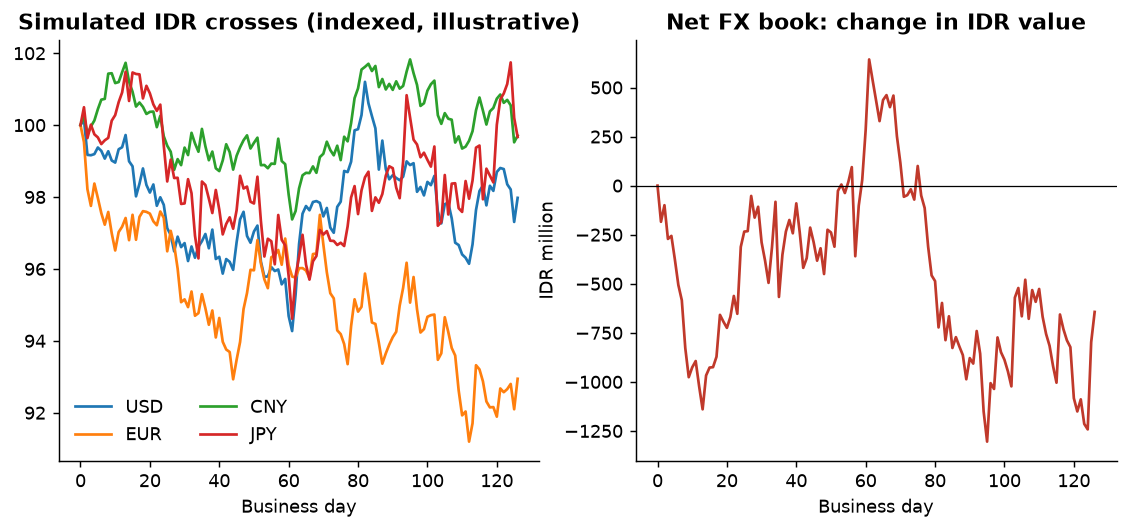

In [3]:
v = fx.parametric_var(case)
tbl = pd.Series(v["standalone"], name="stand-alone VaR (IDR bn)") / 1e9
display(tbl.to_frame().style.format("{:,.2f}"))
print(f"Sum of stand-alone VaRs (no diversification): IDR {v['undiversified']/1e9:,.2f} bn")
print(f"Diversified portfolio VaR                    : IDR {v['diversified']/1e9:,.2f} bn  (z = {v['z']:.3f})")
paths = fx.simulate_paths(case)
display(Image(plots.plot_fx_paths(case, paths, net["net_fcy"])))

Summing stand-alone VaRs overstates risk when currencies are imperfectly correlated; the diversified figure is lower.
(The course workbook summed stand-alone figures; see the audit in the DCF notebook.)

## 3. Hedge comparison (Monte Carlo, 6-month tenor)

,spot,forward (CIP),forward premium
USD,"16,500","16,621.32",0.74%
EUR,"18,000","18,266.67",1.48%
CNY,"2,300","2,345.66",1.99%
JPY,110,112.74,2.49%


,mean P&L (IDR mn),std dev (IDR mn),99% worst-case P&L (IDR mn),risk reduction vs unhedged
Unhedged,19.0,"1,709.1","-4,111.0",0%
Natural hedge (re-invoice CNY sales),12.8,"1,239.8","-2,931.2",27%
Forward 50%,-458.1,854.5,"-2,523.1",50%
Forward 100%,-935.2,0.0,-935.2,100%
Options 100% (ATM-forward strike),-368.8,"1,402.8","-2,620.1",18%
Natural + forward on residual,-569.9,0.0,-569.9,100%


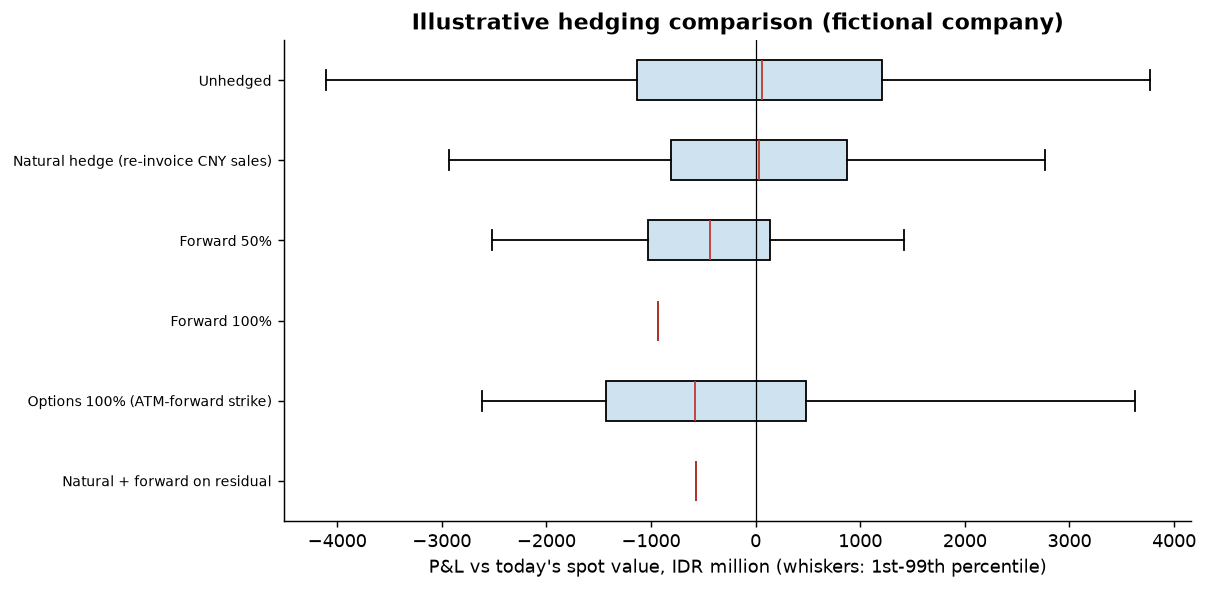

In [4]:
t = case["horizon_days"] / case["business_days_per_year"]
fw = pd.DataFrame({
    "spot": [case["spot_idr"][k] for k in fx.CCYS],
    "forward (CIP)": [fx.forward_rate(case["spot_idr"][k], case["rates"]["IDR"], case["rates"][k], t) for k in fx.CCYS],
}, index=fx.CCYS)
fw["forward premium"] = fw["forward (CIP)"] / fw["spot"] - 1
display(fw.style.format({"spot": "{:,.0f}", "forward (CIP)": "{:,.2f}", "forward premium": "{:.2%}"}))
summary, samples = fx.hedge_comparison(case)
display(summary.style.format("{:,.1f}", subset=summary.columns[:3]).format("{:.0%}", subset=summary.columns[3:]))
display(Image(plots.plot_hedge_distribution(samples, case["confidence"])))

**What to take from it**

- A 100% forward removes variance but locks in the **forward points**: because IDR rates are above foreign rates, buying
  CNY/JPY forward costs more than spot. That carry is the negative mean P&L, a real cost of the hedge
  even though spot is simulated with zero drift.
- Options keep the favourable tail but cost a premium up front, so mean P&L is lower than unhedged and variance falls less.
- A natural hedge (re-invoicing part of sales in CNY) reduces exposure at no instrument cost, but only as far as commercial
  terms allow. Combining it with a forward on the residual is the cheapest way to reach zero variance here.
- Not modelled: hedge accounting (PSAK 71 / IFRS 9), bank spreads, credit lines, basis risk, hedging forecast (not yet
  recognised) cash flows, and any view on the direction of rates.

*Illustrative and fictional; educational analysis, not investment advice.*